# 01 — Veri hazırlama ve EDA

Online Retail II verisini iki çalışma sayfasından okuyup sepetlere dönüştürüyoruz. SEED=7017 ile **temizlemeden önce 50.000 farklı fatura** seçilir. Özel örnekleme kuralı nedeniyle ayrıca %80 örnekleme yapılmaz. Hücreleri sırayla çalıştırın; ham veri ve ara önbellek Git deposuna eklenmez.

In [1]:
import os
import json
import hashlib
import math
import statistics
import time
from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from openpyxl import load_workbook
from mlxtend.frequent_patterns import apriori, fpgrowth

SEED = 7017
ROOT = Path.cwd()
if not (ROOT/'requirements.txt').exists():
    ROOT = ROOT.parent
WORK = Path(os.environ.get('RETAIL_NOTEBOOK_WORK', ROOT/'work'/'notebooks'))
WORK.mkdir(parents=True, exist_ok=True)

EXCLUDED = {'POST', 'DOT', 'M', 'BANK CHARGES', 'ADJUST', 'D', 'S', 'AMAZONFEE', 'B', 'PADS'}


## Dosya ve örneklem

Veri dosyasını `data/online_retail_II.xlsx` konumuna yerleştirin. Resmî indirme betiği proje kökündeki `download_data.py` dosyasıdır. İstenirse `RETAIL_DATA_PATH` ortam değişkeniyle farklı bir yol kullanılabilir.

In [2]:
source = Path(os.environ.get('RETAIL_DATA_PATH', ROOT/'data'/'online_retail_II.xlsx'))
if not source.is_file():
    raise FileNotFoundError(f'Veri dosyası bulunamadı: {source}')
digest = hashlib.sha256(source.read_bytes()).hexdigest()
assert digest == 'bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980'
print('Kaynak SHA256:', digest)


Kaynak SHA256: bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980


In [3]:
def sample_invoice_ids(invoice_ids, count=50000, seed=SEED):
    unique = pd.Series(invoice_ids, dtype='object').drop_duplicates()
    return unique.sample(n=count, random_state=seed, replace=False).tolist()

def cache_policy():
    return dict(version=4, seed=SEED, raw_invoice_sample_size=50000, excluded_codes=sorted(EXCLUDED), sampling_order='source encounter order', duplicate_policy='cross-sheet multiset union; within-sheet multiplicity preserved')

def save(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')


In [4]:
inventory = Counter()

inventory_workbook = load_workbook(source, read_only=True, data_only=True)

for sheet in inventory_workbook:
    for row in sheet.iter_rows(min_row=2, values_only=True):
        if row[0] is not None:
            inventory[str(row[0])] += 1

inventory_workbook.close()

selected_ids = sample_invoice_ids(list(inventory), count=50000, seed=SEED)

selected_set = set(selected_ids)

sample_metadata = dict(unit='invoice', requested_n=50000, seed=SEED, stage='raw invoice identifiers before cleaning; all rows of each selected invoice retained', population_invoices=len(inventory), sampled_invoices=len(selected_ids), selected_source_rows=sum((inventory[i] for i in selected_ids)), method=f'pandas.Series.drop_duplicates source encounter order; sample(n=50000, random_state={SEED})', selected_invoice_sha256=hashlib.sha256('\n'.join(selected_ids).encode('utf-8')).hexdigest(), assignment_reference='PDF section 8.1, page 5; supersedes generic 80% sampling on page 1')

print('Raw invoice selection:', sample_metadata, flush=True)


Raw invoice selection: {'unit': 'invoice', 'requested_n': 50000, 'seed': 7017, 'stage': 'raw invoice identifiers before cleaning; all rows of each selected invoice retained', 'population_invoices': 53628, 'sampled_invoices': 50000, 'selected_source_rows': 992390, 'method': 'pandas.Series.drop_duplicates source encounter order; sample(n=50000, random_state=7017)', 'selected_invoice_sha256': 'b11b2be8dd3b9ecac1d4feee94e0a096c15a88f9dd6cc53760613d94a0f92670', 'assignment_reference': 'PDF section 8.1, page 5; supersedes generic 80% sampling on page 1'}


## Satır temizliği ve sepetler

İptaller, pozitif olmayan tutarlar ve hizmet kodları çıkarılır. Müşteri numarası eksik olan faturalar tutulur. İki sayfa arasındaki örtüşme çokluk korunarak giderilir; aynı sayfadaki tekrarlar topluca silinmez.

In [5]:
workbook = load_workbook(source, read_only=True, data_only=True)

previous = Counter()

invoices = {}

audit = Counter()

descriptions = {}

missing = Counter()

excluded = Counter()

for sheet in workbook:
    current = Counter()
    for row in sheet.iter_rows(min_row=2, values_only=True):
        audit['source_raw_rows'] += 1
        if row[0] is None or str(row[0]) not in selected_set:
            audit['outside_invoice_sample_rows'] += 1
            continue
        audit['raw_rows'] += 1
        current[row] += 1
        if current[row] <= previous[row]:
            audit['cross_sheet_duplicates'] += 1
            continue
        inv, sku, desc, qty, date, price, customer, country = row
        for name, value in zip(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country'], row):
            if value is None:
                missing[name] += 1
        if inv is None or sku is None or qty is None or (price is None) or (date is None):
            audit['missing_required_fields'] += 1
            continue
        if str(inv).upper().startswith('C') or qty <= 0 or price <= 0:
            audit['cancelled_or_nonpositive'] += 1
            continue
        sku = str(sku).strip()
        if sku.upper() in EXCLUDED:
            audit['excluded_nonmerchandise_rows'] += 1
            excluded[sku] += 1
            continue
        audit['retained_rows'] += 1
        iid = str(inv)
        if iid not in invoices:
            invoices[iid] = {'invoice': iid, 'date': date.isoformat(), 'products': set()}
        invoices[iid]['date'] = min(invoices[iid]['date'], date.isoformat())
        invoices[iid]['products'].add(sku)
        if desc:
            descriptions.setdefault(sku, str(desc).strip())
    previous |= current

workbook.close()

baskets = []

for item in invoices.values():
    item['products'] = sorted(item['products'])
    baskets.append(item)

baskets.sort(key=lambda b: (b['date'], b['invoice']))

assert sum((audit[k] for k in ['cross_sheet_duplicates', 'missing_required_fields', 'cancelled_or_nonpositive', 'excluded_nonmerchandise_rows', 'retained_rows'])) == audit['raw_rows']

assert audit['raw_rows'] == sample_metadata['selected_source_rows']

assert audit['source_raw_rows'] == audit['raw_rows'] + audit['outside_invoice_sample_rows']

sample_metadata['eligible_invoices_after_cleaning'] = len(baskets)

result = dict(version=4, cache_policy=cache_policy(), sha256=digest, sampling=sample_metadata, audit=dict(audit), missing_after_overlap=dict(missing), excluded_codes=dict(excluded), descriptions=descriptions, baskets=baskets)
data = result
save(WORK/'clean.json', data)
display(pd.Series(data['audit'], name='Satır sayısı').to_frame())


,Satır sayısı
source_raw_rows,1067371
raw_rows,992390
retained_rows,945088
excluded_nonmerchandise_rows,3962
cancelled_or_nonpositive,23330
outside_invoice_sample_rows,74981
cross_sheet_duplicates,20010


## Zaman sırasına göre ayırma

Yaklaşık %60 eğitim, %20 doğrulama ve %20 test kullanılır. Gün sınırları bütün tutulur; aynı fatura iki bölüme girmez.

In [6]:
def chronological_split(baskets):
    first = baskets[int(len(baskets) * 0.6)]['date'][:10]
    second = baskets[int(len(baskets) * 0.8)]['date'][:10]
    train = [b for b in baskets if b['date'][:10] < first]
    valid = [b for b in baskets if first <= b['date'][:10] < second]
    test = [b for b in baskets if b['date'][:10] >= second]
    assert max((b['date'] for b in train)) < min((b['date'] for b in valid))
    assert max((b['date'] for b in valid)) < min((b['date'] for b in test))
    assert len(train) + len(valid) + len(test) == len(baskets)
    return (train, valid, test)

train, valid, test = chronological_split(data['baskets'])
splits = {name: dict(invoices=len(rows), date_min=rows[0]['date'], date_max=rows[-1]['date'])
          for name, rows in [('train', train), ('validation', valid), ('test', test)]}
audit = dict(seed=SEED, source_sha256=data['sha256'], audit=data['audit'],
             missing_after_overlap=data['missing_after_overlap'], excluded_codes=data['excluded_codes'],
             splits=splits, sampling=data['sampling'])
save(WORK/'data_audit.json', audit)
display(pd.DataFrame(splits).T)


,invoices,date_min,date_max
train,22066,2009-12-01T07:45:00,2011-03-03T19:21:00
validation,7345,2011-03-04T08:10:00,2011-08-17T20:02:00
test,7413,2011-08-18T06:20:00,2011-12-09T12:50:00


## Keşifsel analiz

Grafikler notebook içinde gösterilir; JPEG kopyaları `work/notebooks/figures` altına kaydedilir. Ürün desteği ve korelasyon yalnız eğitim döneminden hesaplanır. Aykırı büyük sepetler otomatik silinmez.

,Eksik (%)
Customer ID,22.412431
Description,0.411567


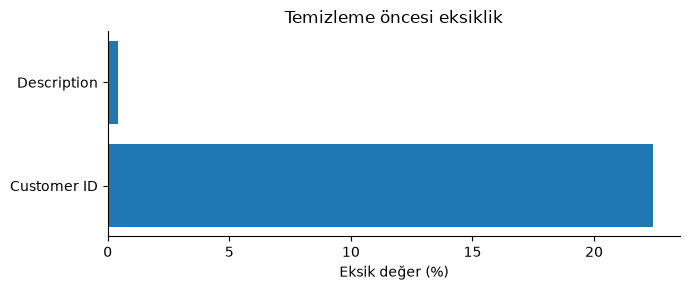

In [7]:
figures = WORK/'figures'
figures.mkdir(exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
def show_figure(fig, name):
    fig.tight_layout()
    fig.savefig(figures/f'{name}.jpeg', dpi=150, pil_kwargs={'quality': 95})
    display(fig)
    plt.close(fig)

baskets = data['baskets']
missing = data['missing_after_overlap']
denominator = data['audit']['raw_rows'] - data['audit']['cross_sheet_duplicates']
display(pd.Series({k: 100*v/denominator for k,v in missing.items()}, name='Eksik (%)').to_frame())
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(list(missing), [100*v/denominator for v in missing.values()])
ax.set(xlabel='Eksik değer (%)', title='Temizleme öncesi eksiklik')
show_figure(fig, '01_eksiklik')


,Sepet büyüklüğü
count,36824.000000
mean,25.083342
std,42.035630
min,1.000000
25%,6.000000
50%,15.000000
75%,29.000000
99%,197.000000
max,1109.000000


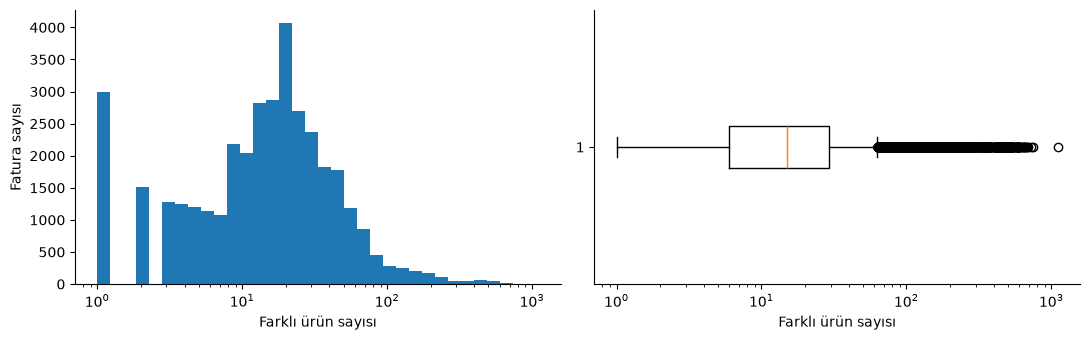

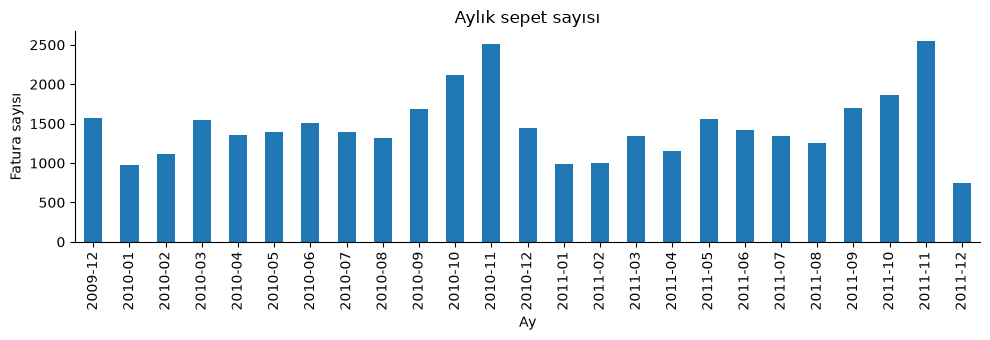

In [8]:
sizes = np.array([len(b['products']) for b in baskets])
display(pd.Series(sizes).describe(percentiles=[.25, .5, .75, .99]).to_frame('Sepet büyüklüğü'))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(sizes, bins=np.geomspace(1, sizes.max()+1, 35))
axes[0].set(xscale='log', xlabel='Farklı ürün sayısı', ylabel='Fatura sayısı')
axes[1].boxplot(sizes, orientation='horizontal')
axes[1].set(xscale='log', xlabel='Farklı ürün sayısı')
show_figure(fig, '02_sepet_buyuklugu')

months = pd.Series(Counter(b['date'][:7] for b in baskets)).sort_index()
fig, ax = plt.subplots(figsize=(10, 3.5))
months.plot.bar(ax=ax)
ax.set(xlabel='Ay', ylabel='Fatura sayısı', title='Aylık sepet sayısı')
show_figure(fig, '03_aylik_sepetler')


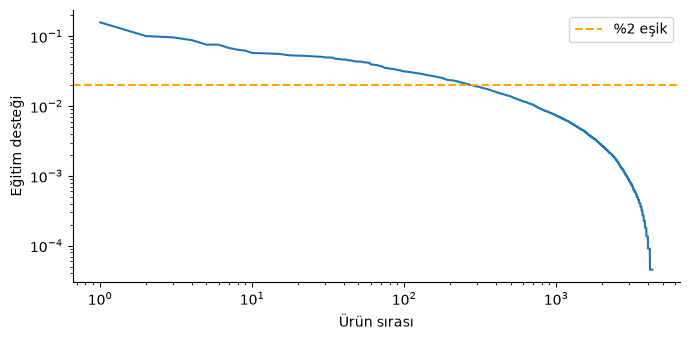

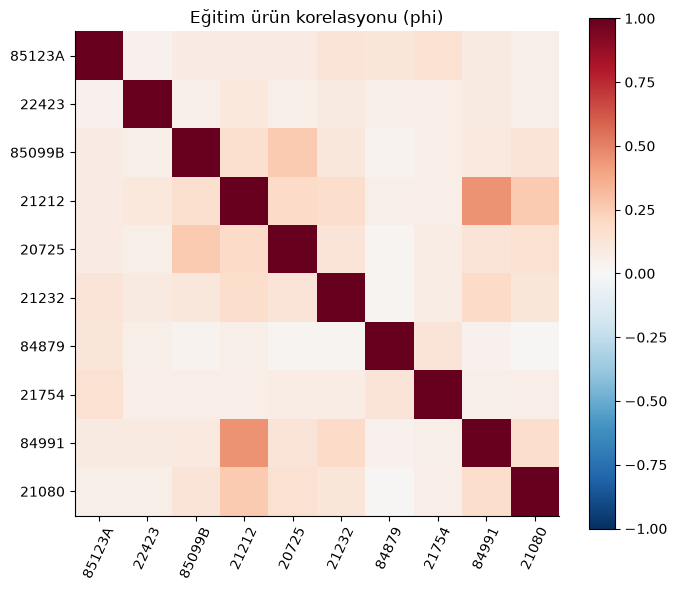

In [9]:
freq = Counter(item for basket in train for item in basket['products'])
supports = sorted((count/len(train) for count in freq.values()), reverse=True)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, len(supports)+1), supports)
ax.axhline(.02, linestyle='--', color='orange', label='%2 eşik')
ax.set(xscale='log', yscale='log', xlabel='Ürün sırası', ylabel='Eğitim desteği')
ax.legend()
show_figure(fig, '04_urun_destegi')

top = sorted(freq, key=lambda item: (-freq[item], item))[:10]
presence = pd.DataFrame([[item in basket['products'] for item in top] for basket in train], columns=top)
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(presence.corr(), vmin=-1, vmax=1, cmap='RdBu_r')
ax.set(xticks=range(10), yticks=range(10), xticklabels=top, yticklabels=top, title='Eğitim ürün korelasyonu (phi)')
ax.tick_params(axis='x', rotation=65)
fig.colorbar(image, ax=ax)
show_figure(fig, '05_korelasyon')


## Sonraki adım

`02_birliktelik_kurallari.ipynb` aynı yerel önbelleği kullanır. Büyük sepetler ve uzun kuyruk sonraki duyarlılık deneylerinde ayrıca incelenir. Fatura ve müşteri kimlikleri gösterilmez.